# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [8]:

import random

# Q1: Card Class
class Card:
    def __init__(self, suit, rank):
        self.suit = suit
        self.rank = rank

    def get_value(self):
        if self.rank in ['J', 'Q', 'K']:
            return 10
        elif self.rank == 'A':
            return 11
        return int(self.rank)

    def to_string(self):
        return f"{self.rank} of {self.suit}"


# Q1: Deck Class
class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.cards = []
        self.plastic_card_index = -1
        self.cards_dealt_since_shuffle = 0
        self.needs_shuffle = False
        self.build_deck()

    def build_deck(self):
        suits = ['spade', 'heart', 'diamond', 'club']
        ranks = ['2', '3', '4', '5', '6', '7',
                 '8', '9', '10', 'J', 'Q', 'K', 'A']

        self.cards = [
            Card(suit, rank)
            for _ in range(self.num_decks)
            for suit in suits
            for rank in ranks
        ]
        self.shuffle()

    def shuffle(self):
        random.shuffle(self.cards)
        total_cards = len(self.cards)

        self.plastic_card_index = random.randint(
            int(total_cards * 0.6),
            int(total_cards * 0.8)
        )

        self.cards_dealt_since_shuffle = 0
        self.needs_shuffle = False

    def draw(self):
        if not self.cards:
            self.build_deck()

        card = self.cards.pop(0)
        self.cards_dealt_since_shuffle += 1

        # Mark the shoe for reshuffling after
        # reaching the plastic card
        if self.cards_dealt_since_shuffle >= self.plastic_card_index:
            self.needs_shuffle = True

        return card, self.needs_shuffle

    def reshuffle_if_needed(self):
        # Call between rounds, not during a round
        if self.needs_shuffle:
            self.build_deck()


In [9]:
# Test Card class
card1 = Card('spade', 'A')
card2 = Card('heart', 'K')
card3 = Card('diamond', '5')

print("Card Tests:")
print(card1.to_string(), "Value:", card1.get_value())
print(card2.to_string(), "Value:", card2.get_value())
print(card3.to_string(), "Value:", card3.get_value())

# Test Deck class
deck = Deck()

print("\nDeck Tests:")
print("Number of decks:", deck.num_decks)
print("Total cards:", len(deck.cards))
print("Plastic card position:", deck.plastic_card_index)

# Test drawing a card
card, needs_shuffle = deck.draw()

print("\nDraw Test:")
print("Card drawn:", card.to_string())
print("Cards remaining:", len(deck.cards))
print("Needs shuffle:", needs_shuffle)

# Test plastic card detection
while not needs_shuffle:
    card, needs_shuffle = deck.draw()

print("\nPlastic Card Test:")
print("Cards dealt:", deck.cards_dealt_since_shuffle)
print("Needs shuffle:", needs_shuffle)

# Test reshuffling
deck.reshuffle_if_needed()

print("\nReshuffle Test:")
print("Cards after reshuffling:", len(deck.cards))
print("Needs shuffle:", deck.needs_shuffle)

# Verify results
assert card1.get_value() == 11
assert card2.get_value() == 10
assert card3.get_value() == 5
assert len(deck.cards) == 312
assert deck.cards_dealt_since_shuffle == 0
assert deck.needs_shuffle is False

print("\nAll Q1 tests passed!")

Card Tests:
A of spade Value: 11
K of heart Value: 10
5 of diamond Value: 5

Deck Tests:
Number of decks: 6
Total cards: 312
Plastic card position: 247

Draw Test:
Card drawn: 2 of heart
Cards remaining: 311
Needs shuffle: False

Plastic Card Test:
Cards dealt: 247
Needs shuffle: True

Reshuffle Test:
Cards after reshuffling: 312
Needs shuffle: False

All Q1 tests passed!


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [10]:
# Q3: Hand Class
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        self.cards.append(card)

    def get_value(self):
        value = 0
        aces = 0

        for card in self.cards:
            value += card.get_value()
            if card.rank == 'A':
                aces += 1

        # Change Ace from 11 to 1 if needed
        while value > 21 and aces > 0:
            value -= 10
            aces -= 1

        return value

    def is_bust(self):
        return self.get_value() > 21

    def is_blackjack(self):
        return len(self.cards) == 2 and self.get_value() == 21

    def __str__(self):
        cards = ", ".join(c.to_string() for c in self.cards)
        return f"{cards} (Total: {self.get_value()})"


# Q3: Player Class
class Player:
    def __init__(self, name, chips=1000):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.current_bet = 0

    def reset_hand(self):
        self.hand = Hand()
        self.current_bet = 0

    def place_bet(self, amount):
        if amount <= 0:
            raise ValueError("Bet must be positive")

        amount = min(amount, self.chips)
        self.current_bet = amount
        self.chips -= amount
        return amount

    def receive_card(self, card, game_state=None):
        self.hand.add_card(card)

    def decide_action(self, dealer_up_card, running_count=0):
        # Hit below 17, otherwise stand
        if self.hand.get_value() < 17:
            return "hit"
        return "stand"


# Q3: Human Player Class
class HumanPlayer(Player):
    def decide_action(self, dealer_up_card, running_count=0):
        while True:
            print(f"\nYour hand: {self.hand}")
            print(f"Dealer up-card: {dealer_up_card.to_string()}")

            choice = input(
                "Enter 'h' to Hit or 's' to Stand: "
            ).strip().lower()

            if choice in ['h', 'hit']:
                return "hit"
            elif choice in ['s', 'stand']:
                return "stand"
            else:
                print("Invalid choice. Try again.")


# Q3: Blackjack Game Class
class BlackjackGame:
    def __init__(self, players, num_decks=6, verbose=True):
        self.deck = Deck(num_decks)
        self.players = players
        self.dealer_hand = Hand()
        self.verbose = verbose
        self.shuffle_pending = False
        self.running_count = 0

    def update_count(self, card):
        if card.rank in ['2', '3', '4', '5', '6']:
            self.running_count += 1
        elif card.rank in ['10', 'J', 'Q', 'K', 'A']:
            self.running_count -= 1

    def log(self, message):
        if self.verbose:
            print(message)

    def draw_card(self, visible=True):
        card, needs_shuffle = self.deck.draw()

        if needs_shuffle:
            self.shuffle_pending = True

        if visible:
            self.update_count(card)

        return card

    def play_round(self, base_bet=10):

        # Reshuffle only between rounds
        if self.shuffle_pending or self.deck.needs_shuffle:
            self.log("\n--- Plastic card reached. Shuffling! ---")
            self.deck.build_deck()
            self.running_count = 0
            self.shuffle_pending = False

        # Find players with chips remaining
        active_players = [
            p for p in self.players if p.chips > 0
        ]

        if not active_players:
            return False

        # Reset hands and place bets
        self.dealer_hand = Hand()

        for p in active_players:
            p.reset_hand()
            p.place_bet(base_bet)

        # Initial deal
        for _ in range(2):
            for p in active_players:
                card = self.draw_card(visible=True)
                p.receive_card(card)

            # Dealer's second card is hidden
            visible = len(self.dealer_hand.cards) == 0
            card = self.draw_card(visible=visible)
            self.dealer_hand.add_card(card)

        dealer_up_card = self.dealer_hand.cards[0]

        self.log(
            f"\n--- New Round "
            f"(Running Count: {self.running_count}) ---"
        )
        self.log(
            f"Dealer shows: {dealer_up_card.to_string()}"
        )

        # Players' turns
        for p in active_players:
            self.log(
                f"\nPlayer {p.name}'s turn "
                f"(Chips: {p.chips + p.current_bet}):"
            )

            # Natural blackjack needs no action
            if p.hand.is_blackjack():
                self.log(f"{p.name} has Blackjack!")
                continue

            while p.hand.get_value() < 21:
                action = p.decide_action(
                    dealer_up_card,
                    self.running_count
                )

                if action == "hit":
                    card = self.draw_card(visible=True)
                    p.receive_card(card)

                    self.log(
                        f"{p.name} hits and gets "
                        f"{card.to_string()}. Hand: {p.hand}"
                    )

                    if p.hand.is_bust():
                        self.log(f"{p.name} Busted!")
                        break

                elif action == "stand":
                    self.log(
                        f"{p.name} stands on "
                        f"{p.hand.get_value()}"
                    )
                    break

                else:
                    raise ValueError(
                        f"Invalid player action: {action}"
                    )

        # Reveal dealer's hidden card
        hidden_card = self.dealer_hand.cards[1]
        self.update_count(hidden_card)

        self.log(
            f"\nDealer's hidden card revealed. "
            f"Hand: {self.dealer_hand}"
        )

        dealer_blackjack = self.dealer_hand.is_blackjack()

        # Dealer hits below 17, unless blackjack
        if not dealer_blackjack:
            while (
                self.dealer_hand.get_value() < 17
                and any(not p.hand.is_bust()
                        for p in active_players)
            ):
                card = self.draw_card(visible=True)
                self.dealer_hand.add_card(card)

                self.log(
                    f"Dealer hits and gets "
                    f"{card.to_string()}. "
                    f"Hand: {self.dealer_hand}"
                )

        dealer_total = self.dealer_hand.get_value()
        dealer_bust = self.dealer_hand.is_bust()

        if dealer_bust:
            self.log("Dealer Busted!")

        # Payouts
        self.log("\n--- Round Results ---")

        for p in active_players:
            bet = p.current_bet
            player_total = p.hand.get_value()
            player_blackjack = p.hand.is_blackjack()

            if p.hand.is_bust():
                self.log(f"{p.name} lost {bet} chips.")

            elif dealer_blackjack:
                if player_blackjack:
                    p.chips += bet
                    self.log(
                        f"{p.name} pushes. Bet returned."
                    )
                else:
                    self.log(
                        f"{p.name} lost {bet} chips."
                    )

            elif player_blackjack:
                # 3:2 blackjack payout
                payout = bet * 2.5
                p.chips += payout
                self.log(
                    f"{p.name} Blackjack! "
                    f"Payout: {payout} chips."
                )

            elif dealer_bust or player_total > dealer_total:
                # Regular win: return bet + equal winnings
                payout = bet * 2
                p.chips += payout
                self.log(
                    f"{p.name} wins! "
                    f"Payout: {payout} chips."
                )

            elif player_total < dealer_total:
                self.log(
                    f"{p.name} lost {bet} chips."
                )

            else:
                p.chips += bet
                self.log(
                    f"{p.name} pushes. Bet returned."
                )

        return True


In [11]:
# Test Hand
hand = Hand()
hand.add_card(Card('spade', 'A'))
hand.add_card(Card('heart', '9'))
hand.add_card(Card('club', '5'))

assert hand.get_value() == 15
assert hand.is_bust() == False
assert hand.is_blackjack() == False
print("Hand tests passed!")

# Test Blackjack
blackjack_hand = Hand()
blackjack_hand.add_card(Card('spade', 'A'))
blackjack_hand.add_card(Card('heart', 'K'))

assert blackjack_hand.is_blackjack() == True
assert blackjack_hand.get_value() == 21
print("Blackjack tests passed!")

# Test Player
player = Player("Test Player", chips=1000)
player.place_bet(10)

assert player.chips == 990
assert player.current_bet == 10

player.receive_card(Card('club', '8'))
player.receive_card(Card('heart', '7'))

assert player.decide_action(Card('spade', 'K')) == "hit"

player.receive_card(Card('diamond', '2'))
assert player.decide_action(Card('spade', 'K')) == "stand"

print("Player tests passed!")

# Test BlackjackGame
players = [
    Player("Player 1"),
    Player("Player 2"),
    Player("Player 3")
]

game = BlackjackGame(players, verbose=False)

for _ in range(5):
    game.play_round()

assert len(game.dealer_hand.cards) >= 2
assert all(p.chips >= 0 for p in players)

print("BlackjackGame tests passed!")
print("\nAll Q3 tests passed!")


Hand tests passed!
Blackjack tests passed!
Player tests passed!
BlackjackGame tests passed!

All Q3 tests passed!


4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [16]:
class HumanPlayer(Player):
    def __init__(self, name, chips=1000):
        super().__init__(name, chips)

    def decide_action(self, dealer_up_card, running_count=0):
        while True:
            print(f"\nYour hand: {self.hand}")
            print(f"Dealer up-card: {dealer_up_card.to_string()}")

            choice = input(
                "Enter 'h' to Hit or 's' to Stand: "
            ).strip().lower()

            if choice in ['h', 'hit']:
                return "hit"
            elif choice in ['s', 'stand']:
                return "stand"
            else:
                print("Invalid choice. Please enter 'h' or 's'.")


# DealerPlayer Class
class DealerPlayer(Player):
    def __init__(self, name, chips=1000):
        super().__init__(name, chips)

    def decide_action(self, dealer_up_card, running_count=0):
        if self.hand.get_value() < 17:
            return "hit"
        return "stand"


5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [17]:
# Create 3 computer players following dealer's strategy
test_players = [
    DealerPlayer(name="DealerBot_1", chips=500),
    DealerPlayer(name="DealerBot_2", chips=500),
    DealerPlayer(name="DealerBot_3", chips=500)
]

# Start game using 6 decks
game_simulation = BlackjackGame(
    players=test_players,
    num_decks=6,
    verbose=True
)

# Run 3 rounds
total_rounds_to_test = 3
rounds_played = 0

for round_number in range(1, total_rounds_to_test + 1):

    print(f"\n{'=' * 40}")
    print(f"ROUND {round_number}")
    print(f"{'=' * 40}")

    # Each player bets 20 chips
    round_active = game_simulation.play_round(base_bet=20)

    if not round_active:
        print("\nAll players have run out of chips.")
        break

    rounds_played += 1

    # Display chip balances after each round
    print(f"\nChip Balances After Round {round_number}:")

    for player in test_players:
        print(f"{player.name}: {player.chips} chips")


# Final results
print(f"\n{'=' * 40}")
print("FINAL GAME RESULTS")
print(f"{'=' * 40}")

for player in test_players:
    net_winnings = player.chips - 500

    print(
        f"Player: {player.name:12} | "
        f"Final Chips: {player.chips:6} | "
        f"Net Winnings: {net_winnings:+6}"
    )


# Q5: Verify game results
assert len(test_players) == 3
assert game_simulation.deck.num_decks == 6
assert rounds_played <= total_rounds_to_test
assert all(player.chips >= 0 for player in test_players)

print("\nAll Q5 tests passed!")



ROUND 1

--- New Round (Running Count: 1) ---
Dealer shows: A of club

Player DealerBot_1's turn (Chips: 500):
DealerBot_1 hits and gets Q of diamond. Hand: 4 of spade, 8 of heart, Q of diamond (Total: 22)
DealerBot_1 Busted!

Player DealerBot_2's turn (Chips: 500):
DealerBot_2 stands on 17

Player DealerBot_3's turn (Chips: 500):
DealerBot_3 hits and gets 9 of spade. Hand: 5 of club, 2 of club, 9 of spade (Total: 16)
DealerBot_3 hits and gets J of diamond. Hand: 5 of club, 2 of club, 9 of spade, J of diamond (Total: 26)
DealerBot_3 Busted!

Dealer's hidden card revealed. Hand: A of club, K of heart (Total: 21)

--- Round Results ---
DealerBot_1 lost 20 chips.
DealerBot_2 lost 20 chips.
DealerBot_3 lost 20 chips.

Chip Balances After Round 1:
DealerBot_1: 480 chips
DealerBot_2: 480 chips
DealerBot_3: 480 chips

ROUND 2

--- New Round (Running Count: -1) ---
Dealer shows: 8 of club

Player DealerBot_1's turn (Chips: 480):
DealerBot_1 hits and gets J of spade. Hand: 4 of heart, 10 of sp

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [18]:
class CardCountingPlayer(Player):
    def __init__(self, name, chips=1000, threshold=0):
        super().__init__(name, chips)
        self.threshold = threshold

    def get_card_count_value(self, card):
        # Hi-Lo Card Counting System
        if card.rank in ['2', '3', '4', '5', '6']:
            return 1
        elif card.rank in ['7', '8', '9']:
            return 0
        elif card.rank in ['10', 'J', 'Q', 'K', 'A']:
            return -1
        return 0

    def decide_action(self, dealer_up_card, running_count=0):
        current_total = self.hand.get_value()

        # Always stand on 21
        if current_total >= 21:
            return "stand"

        # Always hit when total is below 12
        if current_total < 12:
            return "hit"

        # Use card-counting strategy
        if running_count <= self.threshold:
            return "hit"
        else:
            return "stand"


In [19]:
# Q6 Testing
player = CardCountingPlayer(
    name="CountingBot",
    chips=1000,
    threshold=0
)

# Test Hi-Lo card values
assert player.get_card_count_value(Card("spade", "2")) == 1
assert player.get_card_count_value(Card("heart", "6")) == 1
assert player.get_card_count_value(Card("club", "8")) == 0
assert player.get_card_count_value(Card("diamond", "K")) == -1
assert player.get_card_count_value(Card("spade", "A")) == -1

print("Hi-Lo counting tests passed!")

# Test threshold strategy
dealer_card = Card("club", "10")

# Hand total = 15
player.receive_card(Card("spade", "10"))
player.receive_card(Card("heart", "5"))

assert player.decide_action(dealer_card, running_count=-2) == "hit"
assert player.decide_action(dealer_card, running_count=0) == "hit"
assert player.decide_action(dealer_card, running_count=3) == "stand"

print("Threshold strategy tests passed!")

# Test low hand value
player.reset_hand()
player.receive_card(Card("spade", "4"))
player.receive_card(Card("heart", "5"))

assert player.decide_action(dealer_card, running_count=5) == "hit"

print("Low hand value test passed!")

# Test 21
player.reset_hand()
player.receive_card(Card("spade", "A"))
player.receive_card(Card("heart", "K"))

assert player.decide_action(dealer_card, running_count=-5) == "stand"

print("Blackjack test passed!")

print("\nAll Q6 tests passed!")


Hi-Lo counting tests passed!
Threshold strategy tests passed!
Low hand value test passed!
Blackjack test passed!

All Q6 tests passed!


7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [ ]:
players = [
    CardCountingPlayer("Counter_Player", chips=1000, threshold=-1),
    Player("Bot_A", chips=1000),
    Player("Bot_B", chips=1000),
    Player("Bot_C", chips=1000)
]

game = BlackjackGame(players, num_decks=6, verbose=False)
initial_chips = 1000

for r in range(50):
    active = game.play_round(base_bet=10)
    if not active or players[0].chips <= 0:
        break

winnings = players[0].chips - initial_chips
print(f"Ending Chips: {players[0].chips} | Net Winnings: {winnings}")

8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


Average Winnings per Round: -3.31 chips
Standard Deviation of Winnings: 84.94 chips
Probability of Net Win: 2.0%
Probability of Net Loss: 97.0%


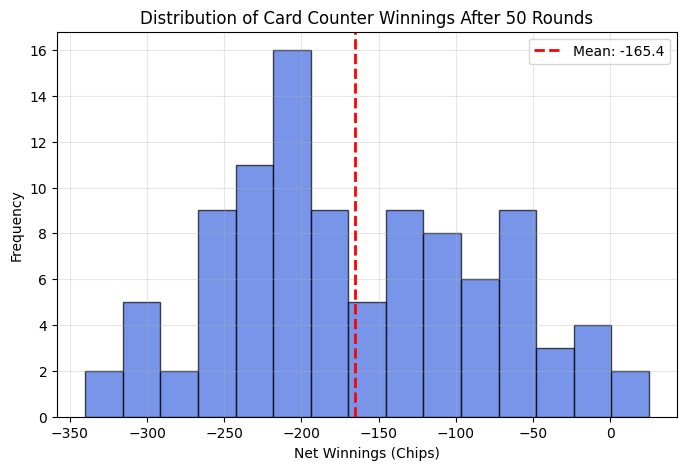

In [20]:
import numpy as np
import matplotlib.pyplot as plt

all_winnings = []
base_bet = 10
rounds_per_game = 50

for _ in range(100):
    players = [
        CardCountingPlayer("Counter_Player", chips=1000, threshold=0),
        Player("Bot_A", chips=1000),
        Player("Bot_B", chips=1000)
    ]
    game = BlackjackGame(players, num_decks=6, verbose=False)

    for r in range(rounds_per_game):
        if players[0].chips <= 0:
            break
        game.play_round(base_bet=base_bet)

    all_winnings.append(players[0].chips - 1000)

# Statistical Output calculations
avg_winnings_per_round = np.mean(all_winnings) / rounds_per_game
std_dev = np.std(all_winnings)
win_prob = np.sum(np.array(all_winnings) > 0) / len(all_winnings)
loss_prob = np.sum(np.array(all_winnings) < 0) / len(all_winnings)

print(f"Average Winnings per Round: {avg_winnings_per_round:.2f} chips")
print(f"Standard Deviation of Winnings: {std_dev:.2f} chips")
print(f"Probability of Net Win: {win_prob * 100:.1f}%")
print(f"Probability of Net Loss: {loss_prob * 100:.1f}%")

# Generate Histogram Plot
plt.figure(figsize=(8, 5))
plt.hist(all_winnings, bins=15, color='royalblue', edgecolor='black', alpha=0.7)
plt.axvline(np.mean(all_winnings), color='red', linestyle='dashed', linewidth=2, label=f'Mean: {np.mean(all_winnings):.1f}')
plt.title("Distribution of Card Counter Winnings After 50 Rounds")
plt.xlabel("Net Winnings (Chips)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

--- Q9: Threshold Comparison ---
Threshold: -4 | Average Winnings: -111.10 | Std Dev:   72.37 | Win Probability:   5.0%
Threshold: -2 | Average Winnings: -145.55 | Std Dev:   73.43 | Win Probability:   1.0%
Threshold:  0 | Average Winnings: -185.90 | Std Dev:   83.81 | Win Probability:   0.0%
Threshold:  2 | Average Winnings: -206.95 | Std Dev:   76.29 | Win Probability:   3.0%
Threshold:  4 | Average Winnings: -244.25 | Std Dev:   79.95 | Win Probability:   0.0%

--- Best Threshold ---
Best Threshold: -4
Highest Average Winnings: -111.10 chips


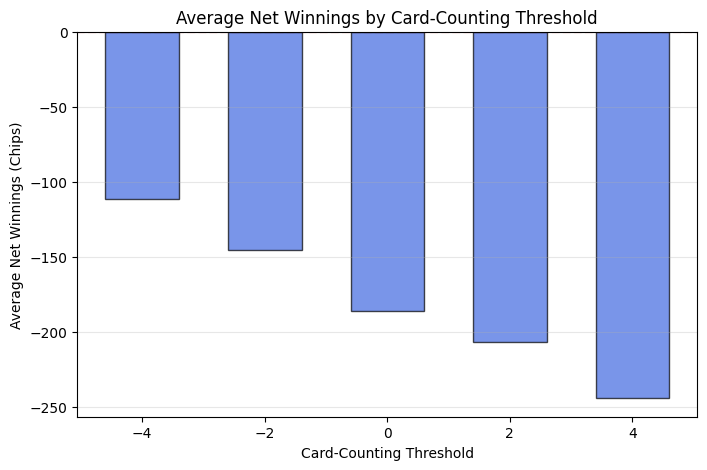


All Q9 tests passed!


In [21]:

# Q9: Find the Best Card-Counting Threshold

import numpy as np
import matplotlib.pyplot as plt

thresholds = [-4, -2, 0, 2, 4]
results = {}

num_simulations = 100
rounds_per_game = 50
initial_chips = 1000
base_bet = 10

# Test each threshold
for t in thresholds:
    t_winnings = []

    for _ in range(num_simulations):

        # Create 1 card counter and 3 dealer-strategy players
        players = [
            CardCountingPlayer("Counter", chips=1000, threshold=t),
            DealerPlayer("Bot_A", chips=1000),
            DealerPlayer("Bot_B", chips=1000),
            DealerPlayer("Bot_C", chips=1000)
        ]

        game = BlackjackGame(
            players,
            num_decks=6,
            verbose=False
        )

        # Run up to 50 rounds
        for _ in range(rounds_per_game):

            if players[0].chips <= 0:
                break

            active = game.play_round(base_bet=base_bet)

            if not active:
                break

        # Record net winnings
        net_winnings = players[0].chips - initial_chips
        t_winnings.append(net_winnings)

    # Calculate statistics for each threshold
    results[t] = {
        "mean": np.mean(t_winnings),
        "std": np.std(t_winnings),
        "win_prob": np.mean(np.array(t_winnings) > 0)
    }


# Display results
print("--- Q9: Threshold Comparison ---")

for t, stats in results.items():
    print(
        f"Threshold: {t:2d} | "
        f"Average Winnings: {stats['mean']:7.2f} | "
        f"Std Dev: {stats['std']:7.2f} | "
        f"Win Probability: {stats['win_prob'] * 100:5.1f}%"
    )


# Find the best threshold
best_threshold = max(
    results,
    key=lambda t: results[t]["mean"]
)

print("\n--- Best Threshold ---")
print(f"Best Threshold: {best_threshold}")
print(
    f"Highest Average Winnings: "
    f"{results[best_threshold]['mean']:.2f} chips"
)


# Plot average winnings for each threshold
plt.figure(figsize=(8, 5))

plt.bar(
    thresholds,
    [results[t]["mean"] for t in thresholds],
    width=1.2,
    color="royalblue",
    edgecolor="black",
    alpha=0.7
)

plt.axhline(0, color="red", linestyle="dashed")

plt.title("Average Net Winnings by Card-Counting Threshold")
plt.xlabel("Card-Counting Threshold")
plt.ylabel("Average Net Winnings (Chips)")
plt.xticks(thresholds)
plt.grid(axis="y", alpha=0.3)
plt.show()


# Q9: Verify results
assert len(results) == 5
assert best_threshold in thresholds
assert all(np.isfinite(results[t]["mean"]) for t in thresholds)

print("\nAll Q9 tests passed!")


10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

--- Q10: Strategy Comparison ---

Strategy: Original Card Counting
Average Net Winnings: -149.75 chips
Average Winnings per Round: -3.00 chips
Standard Deviation: 83.62 chips
Probability of Net Win: 4.0%

Strategy: Improved Card Counting
Average Net Winnings: -25.50 chips
Average Winnings per Round: -0.51 chips
Standard Deviation: 71.70 chips
Probability of Net Win: 32.0%

--- Final Comparison ---
Difference in Average Winnings: +124.25 chips
The improved strategy performed better.


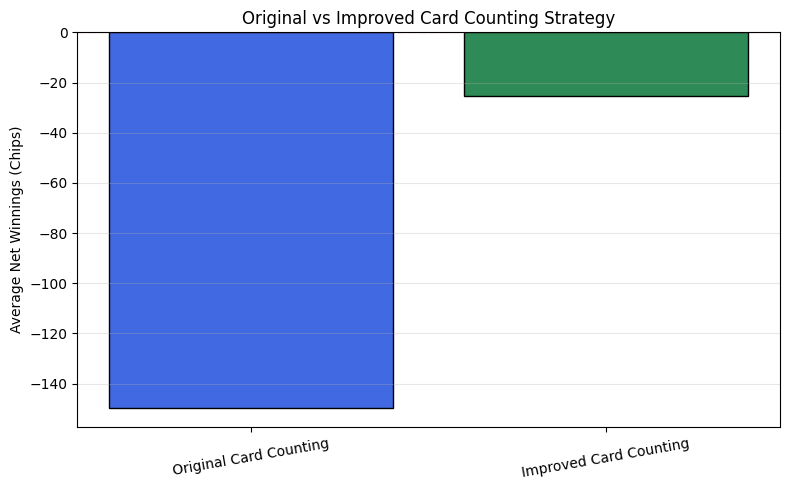


All Q10 tests passed!


In [23]:
# Create and Test a New Blackjack Strategy
import numpy as np
import matplotlib.pyplot as plt

# New Strategy: Combine hand value, dealer card, and running count
class ImprovedCountingPlayer(CardCountingPlayer):
    def decide_action(self, dealer_up_card, running_count=0):
        total = self.hand.get_value()
        dealer_value = dealer_up_card.get_value()

        # Always hit on 11 or less
        if total <= 11:
            return "hit"

        # Always stand on 17 or higher
        if total >= 17:
            return "stand"

        # For hands between 12 and 16
        if dealer_value >= 7:
            return "hit"

        # Against a weak dealer card, use running count
        if running_count <= self.threshold - 2:
            return "hit"

        return "stand"


# Test original and improved strategies
num_simulations = 100
rounds_per_game = 50
initial_chips = 1000
base_bet = 10

results_q10 = {}

strategies = {
    "Original Card Counting": CardCountingPlayer,
    "Improved Card Counting": ImprovedCountingPlayer
}

for strategy_name, strategy_class in strategies.items():

    winnings = []
    total_rounds = 0

    for _ in range(num_simulations):

        players = [
            strategy_class("Counter", chips=1000, threshold=-1),
            DealerPlayer("Bot_A", chips=1000),
            DealerPlayer("Bot_B", chips=1000),
            DealerPlayer("Bot_C", chips=1000)
        ]

        game = BlackjackGame(
            players,
            num_decks=6,
            verbose=False
        )

        rounds_played = 0

        for _ in range(rounds_per_game):
            if players[0].chips <= 0:
                break

            active = game.play_round(base_bet=base_bet)

            if not active:
                break

            rounds_played += 1

        winnings.append(players[0].chips - initial_chips)
        total_rounds += rounds_played

    winnings = np.array(winnings)

    results_q10[strategy_name] = {
        "mean": np.mean(winnings),
        "std": np.std(winnings),
        "per_round": np.sum(winnings) / total_rounds,
        "win_prob": np.mean(winnings > 0),
        "winnings": winnings
    }


# Display comparison
print("--- Q10: Strategy Comparison ---")

for name, stats in results_q10.items():
    print(f"\nStrategy: {name}")
    print(f"Average Net Winnings: {stats['mean']:.2f} chips")
    print(f"Average Winnings per Round: {stats['per_round']:.2f} chips")
    print(f"Standard Deviation: {stats['std']:.2f} chips")
    print(f"Probability of Net Win: {stats['win_prob'] * 100:.1f}%")


# Compare the two strategies
original = results_q10["Original Card Counting"]["mean"]
improved = results_q10["Improved Card Counting"]["mean"]

difference = improved - original

print("\n--- Final Comparison ---")
print(f"Difference in Average Winnings: {difference:+.2f} chips")

if difference > 0:
    print("The improved strategy performed better.")
elif difference < 0:
    print("The improved strategy performed worse.")
else:
    print("Both strategies had equal average winnings.")


# Bar chart
names = list(results_q10.keys())
means = [results_q10[name]["mean"] for name in names]

plt.figure(figsize=(8, 5))

plt.bar(
    names,
    means,
    color=["royalblue", "seagreen"],
    edgecolor="black"
)

plt.axhline(0, color="red", linestyle="dashed")
plt.title("Original vs Improved Card Counting Strategy")
plt.ylabel("Average Net Winnings (Chips)")
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Verify results
assert len(results_q10) == 2
assert all(len(stats["winnings"]) == 100
           for stats in results_q10.values())

print("\nAll Q10 tests passed!")
